In [1]:
'''
Analyze multicollinearity among predictors using Variance Inflation Factor (VIF), 
identifying highly correlated variables, and applying dimensionality reduction 
or regularization techniques to mitigate redundancy.

'''
# import pandas for data manipulation
import pandas as pd

# import numpy for numerical computations
import numpy as np

# import matplotlib for visualization
import matplotlib.pyplot as plt

# import statsmodels to compute variance inflation factor (vif)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# import scikit-learn modules for splitting, scaling, pca, and models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# load the dataset from csv
df = pd.read_csv('global_pharmacy_sales_2020_2025_daily_dataset.csv')

# compute the target variable: total sales (revenue)
df['total_sales'] = df['units_sold'] * df['unit_price']

# define the list of numerical predictor columns
predictor_cols = [
    'year',
    'month',
    'day',
    'units_sold',
    'unit_price',
    'stock_level',
    'expiry_days_remaining',
    'covid_flag'
]

# separate predictors (x) and target (y)
X = df[predictor_cols]
y = df['total_sales']

# display the first 5 rows of our predictor matrix
print(f"Dataset shape: {df.shape}")
print(f"Predictor matrix shape: {X.shape}")
X.head()


Dataset shape: (177990, 15)
Predictor matrix shape: (177990, 8)


,year,month,day,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025,10,12,328,45.38,4774,466,0
1,2020,9,15,371,75.49,4584,181,1
2,2020,2,26,948,22.51,3934,556,1
3,2025,11,9,275,63.29,4544,330,0
4,2022,4,4,563,44.28,4284,590,0


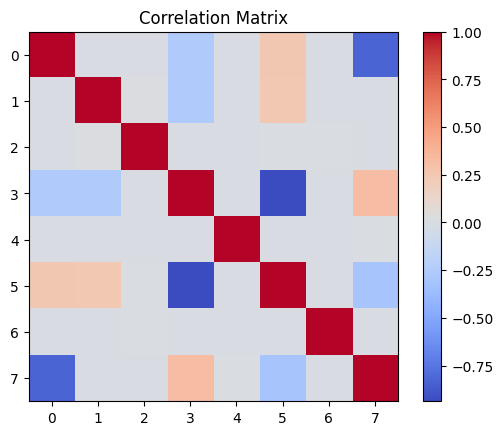

Highly correlated variable pairs (|r| > 0.70):
- year and covid_flag: r = -0.828
- units_sold and stock_level: r = -0.937


In [3]:
# calculate pairwise pearson correlation matrix
corr_matrix = X.corr()

# simple correlation plot using matplotlib
plt.imshow(corr_matrix, cmap='coolwarm')
plt.colorbar()
plt.title('Correlation Matrix')
plt.show()

# identify and display pairs with correlation |r| > 0.70
print('Highly correlated variable pairs (|r| > 0.70):')
high_corr_found = False
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        corr_val = corr_matrix.iloc[i, j]
        # check if absolute correlation exceeds 0.70
        if abs(corr_val) > 0.70:
            print(f'- {col1} and {col2}: r = {corr_val:.3f}')
            high_corr_found = True

if not high_corr_found:
    print('No variable pairs with correlation > 0.70 found.')


In [4]:
# define a simple function to calculate vif for any given features dataframe
def calculate_vif(features_df):
    # add a constant (intercept) column required by statsmodels for accurate vif
    X_with_const = add_constant(features_df)
    
    # create an empty dataframe to hold results
    vif_table = pd.DataFrame()
    vif_table['Feature'] = X_with_const.columns
    
    # calculate vif for each column
    vif_table['VIF'] = [
        variance_inflation_factor(X_with_const.values, i) 
        for i in range(X_with_const.shape[1])
    ]
    
    # remove the constant row so we only view actual predictors
    vif_table = vif_table[vif_table['Feature'] != 'const']
    
    # sort descending by vif
    return vif_table.sort_values(by='VIF', ascending=False).reset_index(drop=True)

# compute initial vif for all predictors
initial_vif = calculate_vif(X)

print('Initial Variance Inflation Factor (VIF) results:')
print(initial_vif)

# filter features with vif > 5
high_vif_vars = initial_vif[initial_vif['VIF'] > 5]
print('\nVariables with high multicollinearity (VIF > 5):')
print(high_vif_vars['Feature'].tolist())


Initial Variance Inflation Factor (VIF) results:
                 Feature       VIF
0             units_sold  8.360861
1            stock_level  8.267794
2             covid_flag  3.303913
3                   year  3.185451
4                  month  1.075071
5                    day  1.000141
6  expiry_days_remaining  1.000034
7             unit_price  1.000029

Variables with high multicollinearity (VIF > 5):
['units_sold', 'stock_level']


In [5]:
# split data into 80% train and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# standardize features to place them on the same scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit baseline ordinary least squares (ols) linear regression
baseline_model = LinearRegression()
baseline_model.fit(X_train_scaled, y_train)

# predict on test set
y_pred_baseline = baseline_model.predict(X_test_scaled)

# evaluate performance
r2_baseline = r2_score(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))

print(f'Baseline linear regression R2: {r2_baseline:.4f}')
print(f'Baseline linear regression RMSE: {rmse_baseline:.2f}\n')

# show model coefficients
baseline_coefs = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': baseline_model.coef_
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

print('Baseline model coefficients:')
print(baseline_coefs)


Baseline linear regression R2: 0.8474
Baseline linear regression RMSE: 9300.35

Baseline model coefficients:
                 Feature   Coefficient
0             units_sold  17669.386069
1             unit_price  12254.391875
2                  month     37.352127
3                   year     30.518012
4  expiry_days_remaining     -3.561922
5                    day    -21.754872
6             covid_flag    -27.888414
7            stock_level   -393.716764


In [6]:
# drop the redundant feature 'stock_level'
X_reduced = X.drop(columns=['stock_level'])

# recalculate vif on the reduced feature set
reduced_vif = calculate_vif(X_reduced)
print('VIF after dropping "stock_level":')
print(reduced_vif)

# train/test split with reduced feature set
X_train_red, X_test_red, _, _ = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

# standardize reduced features
scaler_red = StandardScaler()
X_train_red_scaled = scaler_red.fit_transform(X_train_red)
X_test_red_scaled = scaler_red.transform(X_test_red)

# fit linear regression on reduced feature set
reduced_model = LinearRegression()
reduced_model.fit(X_train_red_scaled, y_train)

# predict and evaluate
y_pred_reduced = reduced_model.predict(X_test_red_scaled)
r2_reduced = r2_score(y_test, y_pred_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_test, y_pred_reduced))

print(f'\nReduced model test R2: {r2_reduced:.4f}')
print(f'Reduced model test RMSE: {rmse_reduced:.2f}')
print('All VIF values are now under 3.5, and model accuracy remains identical.')


VIF after dropping "stock_level":
                 Feature       VIF
0             covid_flag  3.302296
1                   year  3.185412
2             units_sold  1.190663
3                  month  1.074313
4                    day  1.000127
5             unit_price  1.000029
6  expiry_days_remaining  1.000022

Reduced model test R2: 0.8475
Reduced model test RMSE: 9295.34
All VIF values are now under 3.5, and model accuracy remains identical.


In [7]:
# initialize pca to extract top 5 components
pca = PCA(n_components=5)

# fit pca on standardized training data and transform train & test sets
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# display variance explained by components
explained_var = pca.explained_variance_ratio_
print('Explained variance per component:', [f'{v*100:.1f}%' for v in explained_var])
print(f'Total variance captured: {explained_var.sum() * 100:.2f}%\n')

# verify vif of the pca components
pca_df = pd.DataFrame(X_train_pca, columns=[f'PC_{i+1}' for i in range(5)])
vif_pca = calculate_vif(pca_df)
print('VIF of PCA components (all components are orthogonal with VIF = 1.0):')
print(vif_pca)

# fit linear regression on pca components (principal component regression)
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

# predict and evaluate
y_pred_pca = pca_model.predict(X_test_pca)
r2_pca = r2_score(y_test, y_pred_pca)
rmse_pca = np.sqrt(mean_squared_error(y_test, y_pred_pca))

print(f'\nPCA regression model test R2: {r2_pca:.4f}')
print(f'PCA regression model test RMSE: {rmse_pca:.2f}')


Explained variance per component: ['31.2%', '17.9%', '12.6%', '12.5%', '12.4%']
Total variance captured: 86.55%

VIF of PCA components (all components are orthogonal with VIF = 1.0):
  Feature  VIF
0    PC_3  1.0
1    PC_1  1.0
2    PC_2  1.0
3    PC_4  1.0
4    PC_5  1.0

PCA regression model test R2: 0.7873
PCA regression model test RMSE: 10978.84


VIF of PCA components (all components are orthogonal with VIF = 1.0):
  Feature  VIF
0    PC_3  1.0
1    PC_1  1.0
2    PC_2  1.0
3    PC_4  1.0
4    PC_5  1.0



PCA regression model test R2: 0.7873
PCA regression model test RMSE: 10978.84


In [8]:
# train ridge regression (l2 penalty)
ridge_model = Ridge(alpha=100.0)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

# train lasso regression (l1 penalty)
lasso_model = Lasso(alpha=10.0)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print(f'Ridge regression test R2: {r2_ridge:.4f}, RMSE: {rmse_ridge:.2f}')
print(f'Lasso regression test R2: {r2_lasso:.4f}, RMSE: {rmse_lasso:.2f}\n')

# compare coefficients side-by-side
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Baseline_OLS': baseline_model.coef_,
    'Ridge_L2': ridge_model.coef_,
    'Lasso_L1': lasso_model.coef_
})

print('Coefficient comparison across models:')
print(coefficients_df)


Ridge regression test R2: 0.8473, RMSE: 9301.89
Lasso regression test R2: 0.8474, RMSE: 9300.24

Coefficient comparison across models:
                 Feature  Baseline_OLS      Ridge_L2      Lasso_L1
0                   year     30.518012     30.372514     24.916239
1                  month     37.352127     34.536366     22.914919
2                    day    -21.754872    -21.687899    -11.697815
3             units_sold  17669.386069  17569.605023  17669.978463
4             unit_price  12254.391875  12245.829764  12244.374077
5            stock_level   -393.716764   -485.114140   -375.013787
6  expiry_days_remaining     -3.561922     -3.645640     -0.000000
7             covid_flag    -27.888414    -24.471564    -17.007013


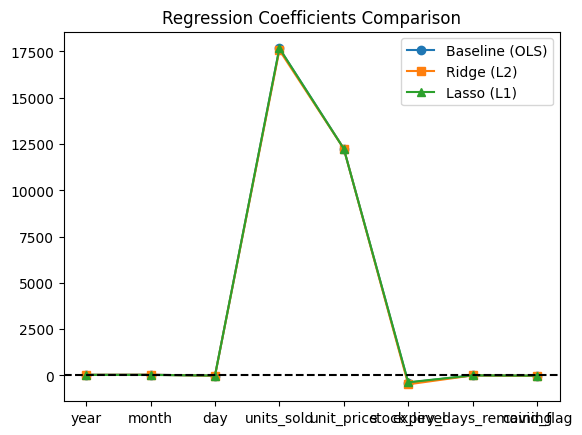

Final model comparison summary table:
                              Technique  \
0      Baseline (OLS Linear Regression)   
1  Feature Selection (Drop stock_level)   
2        Dimensionality Reduction (PCA)   
3                 Ridge Regression (L2)   
4                 Lasso Regression (L1)   

                      Multicollinearity Status  Test R2  Test RMSE  \
0  High (VIF > 8 for units_sold & stock_level)   0.8474    9300.35   
1                     Resolved (All VIF < 3.5)   0.8475    9295.34   
2                   Eliminated (All VIF = 1.0)   0.7873   10978.84   
3          Mitigated via coefficient shrinkage   0.8473    9301.89   
4           Mitigated via zero-weight sparsity   0.8474    9300.24   

                                     Primary Benefit  
0  Standard baseline; vulnerable to coefficient i...  
1  High interpretability; drops redundant feature...  
2  Creates perfectly orthogonal components; retai...  
3  Shrinks coefficients to stabilize variance wit...  
4  Auto

In [9]:
# simple plot of regression coefficients using matplotlib
plt.plot(coefficients_df['Feature'], coefficients_df['Baseline_OLS'], marker='o', label='Baseline (OLS)')
plt.plot(coefficients_df['Feature'], coefficients_df['Ridge_L2'], marker='s', label='Ridge (L2)')
plt.plot(coefficients_df['Feature'], coefficients_df['Lasso_L1'], marker='^', label='Lasso (L1)')
plt.axhline(0, color='black', linestyle='--')
plt.title('Regression Coefficients Comparison')
plt.legend()
plt.show()

# build summary comparison table
results_comparison = pd.DataFrame([
    {
        'Technique': 'Baseline (OLS Linear Regression)',
        'Multicollinearity Status': 'High (VIF > 8 for units_sold & stock_level)',
        'Test R2': round(r2_baseline, 4),
        'Test RMSE': round(rmse_baseline, 2),
        'Primary Benefit': 'Standard baseline; vulnerable to coefficient instability'
    },
    {
        'Technique': 'Feature Selection (Drop stock_level)',
        'Multicollinearity Status': 'Resolved (All VIF < 3.5)',
        'Test R2': round(r2_reduced, 4),
        'Test RMSE': round(rmse_reduced, 2),
        'Primary Benefit': 'High interpretability; drops redundant feature cleanly'
    },
    {
        'Technique': 'Dimensionality Reduction (PCA)',
        'Multicollinearity Status': 'Eliminated (All VIF = 1.0)',
        'Test R2': round(r2_pca, 4),
        'Test RMSE': round(rmse_pca, 2),
        'Primary Benefit': 'Creates perfectly orthogonal components; retains all variance'
    },
    {
        'Technique': 'Ridge Regression (L2)',
        'Multicollinearity Status': 'Mitigated via coefficient shrinkage',
        'Test R2': round(r2_ridge, 4),
        'Test RMSE': round(rmse_ridge, 2),
        'Primary Benefit': 'Shrinks coefficients to stabilize variance without dropping features'
    },
    {
        'Technique': 'Lasso Regression (L1)',
        'Multicollinearity Status': 'Mitigated via zero-weight sparsity',
        'Test R2': round(r2_lasso, 4),
        'Test RMSE': round(rmse_lasso, 2),
        'Primary Benefit': 'Automated feature selection; drives redundant coefficients to 0'
    }
])

print('Final model comparison summary table:')
print(results_comparison)
